# IND320 project 2026
Philip A. K. Øvland \
Github:     https://github.com/Povland/IND320 \
Streamlit:  https://ind320-2026.streamlit.app/

Video explaining stuff (Please tell me if the link doesn't work): TO DO

## AI Usage

I used AI as a helping hand with:
    - planning
    - bug fixing
    - first version of code blocks
    - making sure I had the correct setup locally
    - giving suggestions to the log, this part, readme and structure.

Getting AI to help with logging (not doing it blindly), helped me remember all the problems I came across.


## Log - Tasks
### Post oblig2 work: To make stuff look nicer
- Renamed and reordered the pages with `st.navigation`, wide layout, version in the sidebar (from `pyproject.toml`).
- Home: connection test on load and with a button, data status box, refresh button.
- New About page. Its text is shared with the info boxes on the other pages.
- Cross-border flow: choose connections by country or one by one, several years and months, direction filter, separate views for pie and plot, full-width plot, titles built from the selection.
- Cleanup: comments, imports, README, `.gitignore`, removed duplicates.

### Accounts and repositories
- They are obviously reused
- On a separate branch (byggeplass)

### API
- Familirazed



# Setup
Imports used throughout the notebook. API access lives in the `ind320` package (`src/ind320/`), and static files (shapefiles, CSV) are read from `data/` (described in `data/data_info`). Everything, including geopandas, is installed with `uv sync`.

In [8]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely

DATA_PATH = Path("../data")

print("Python:", sys.version.split()[0])
print("Running from:", Path.cwd())

Python: 3.11.16
Running from: c:\Users\povla\Desktop\gitto\IND320\notebooks


In [9]:
# geopandas reads the zip files directly, no need to unzip.
# NVE_Region has no encoding file, so utf-8 is set by hand (otherwise "RØ" turns into "RÃ\x98")
price_areas = gpd.read_file(DATA_PATH / "Budområder.zip")
nve_regions = gpd.read_file(DATA_PATH / "NVE_Region.zip", encoding="utf-8")

print("CRS:", price_areas.crs, "and", nve_regions.crs)
print("Price areas:", list(price_areas["budomr"]))
print("NVE regions:", list(nve_regions["REGION"]))

CRS: EPSG:25833 and EPSG:25833
Price areas: ['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
NVE regions: ['RV', 'RM', 'RN', 'RØ', 'RS']


### Shapefiles from NVE Atlas
Downloaded from https://atlas.nve.no on 09.11.2026 (see `data/data_info`):
- `Budområder.zip` (Nettanlegg > Nettområder > Budområder): the price areas NO1–NO5, matching `area_type = EL`
- `NVE_Region.zip` (Administrasjon > Administrative områder > NVE_Region): NVE's five regions, merged into the watercourse areas `area_type = VASS`

| VASS area_nr | Area | NVE regions |
|---|---|---|
| 1 | East | RS + RØ |
| 2 | West | RV |
| 3 | North | RM + RN |

NVE's area list describes VASS 3 as Midt-Norge down to southern Nordland, with VASS 4 for the rest of the north. But VASS 4 has no data (see Oblig2), and NVE's weekly report says area 3 covers Nord-Norge too, so RN goes into VASS 3, as the task says.

Both layers follow watersheds, so the NVE regions are close to the price areas (RØ ≈ NO1, RS ≈ NO2, RV ≈ NO5, RM ≈ NO3, RN ≈ NO4). The main difference is in the north: RM goes up to Saltfjellet, while NO3 stops at Tunnsjødal.

### Same area numbers as the reservoir data
Both layers get the columns `area_type` and `area_nr`, so they can be joined with the reservoir data later.

In [10]:
# Price areas: "NO 1" -> area_nr 1
price_areas["area_type"] = "EL"
price_areas["area_nr"] = price_areas["budomr"].str.replace("NO", "").str.strip().astype(int)
price_areas = price_areas[["area_type", "area_nr", "geometry"]]

# Watercourse areas: the five NVE regions merged into the three VASS areas
REGION_TO_VASS = {"RS": 1, "RØ": 1, "RV": 2, "RM": 3, "RN": 3}

nve_regions["area_nr"] = nve_regions["REGION"].map(REGION_TO_VASS)

# Every region must get a VASS number, otherwise dissolve silently drops it
assert nve_regions["area_nr"].notna().all(), nve_regions.loc[nve_regions["area_nr"].isna(), "REGION"].tolist()

vass_areas = nve_regions.dissolve(by="area_nr").reset_index()
vass_areas["area_type"] = "VASS"
vass_areas = vass_areas[["area_type", "area_nr", "geometry"]]

# All areas in one table, 5 EL + 3 VASS = 8 rows
areas = pd.concat([price_areas, vass_areas], ignore_index=True)

# Number of points (vertices) that make up each polygon's outline. Islands and fjords add a lot
areas["n_vertices"] = shapely.get_num_coordinates(areas.geometry)
areas

,area_type,area_nr,geometry,n_vertices
0,EL,1,"POLYGON ((337473.63 6970542.97, 337711.9 69703...",17934
1,EL,2,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0...",5060
2,EL,3,"POLYGON ((308588.7 7261519.43, 313576.63 72590...",5141
3,EL,4,"POLYGON ((973920.93 7962739.19, 974922.77 7962...",16046
4,EL,5,"POLYGON ((101466.43 6881318.54, 101525.43 6881...",10329
5,VASS,1,"POLYGON ((244204.94 6521981.68, 231754.99 6523...",9725
6,VASS,2,"POLYGON ((193105.76 6929797.839, 191705.75 692...",3123
7,VASS,3,"POLYGON ((522969.98 7381455.32, 520050.96 7378...",11176


### Clipping to land
Both layers go out into the sea along the coast. The weather data is meant to explain reservoir filling, and only precipitation on land can reach a reservoir. Without clipping, the share of points at sea would equal the share of area at sea, which is large for the northern areas, and the region averages would partly describe ocean weather. The areas are therefore clipped to the land of Norway before sampling.

An even closer match would be to sample only inside the catchments that drain to hydropower intakes, but land is a simple and reasonable approximation.

In [11]:
# Land of Norway from NVE Atlas (Administrasjon > Administrative områder > Norge_N5000).
# If the file is missing, the areas are used as they are, sea included
LAND_PATH = DATA_PATH / "Norge_N5000.zip"

if LAND_PATH.exists():
    norway = gpd.read_file(LAND_PATH).to_crs(areas.crs)
    areas = gpd.clip(areas, norway)
    print("Clipped to land")
else:
    print(f"{LAND_PATH} not found, areas include the sea")

Clipped to land


### Sampling 100 random locations per area
The task asks for 1000 locations per area, but because of Open-Meteo's free limit, I choose 100.

Random points are drawn inside each area's bounding box, and only those inside the area are kept, until there are 100.
The sampling is done in meters (EPSG:25833), so the points are evenly spread. The result is converted to latitude and longitude for the weather API.
A fixed seed gives the same points every time the notebook runs.

In [ ]:
POINTS_PER_AREA = 100
SEED = 320

rng = np.random.default_rng(SEED)
samples = []

for area_type, area_nr, polygon in zip(areas["area_type"], areas["area_nr"], areas.geometry):
    min_x, min_y, max_x, max_y = polygon.bounds
    xs, ys = [], []

    # Draws points in the bounding box and keeps those inside the area, until there are enough
    while len(xs) < POINTS_PER_AREA:
        x = rng.uniform(min_x, max_x, POINTS_PER_AREA)
        y = rng.uniform(min_y, max_y, POINTS_PER_AREA)
        inside = shapely.contains_xy(polygon, x, y)
        xs.extend(x[inside])
        ys.extend(y[inside])

    samples.append(gpd.GeoDataFrame(
        {"area_type": area_type, "area_nr": area_nr},
        index=range(POINTS_PER_AREA),
        geometry=gpd.points_from_xy(xs[:POINTS_PER_AREA], ys[:POINTS_PER_AREA]),
        crs=areas.crs,
    ))

# Meters -> latitude and longitude for the weather API
locations = pd.concat(samples, ignore_index=True).to_crs(4326)
locations["lat"] = locations.geometry.y
locations["lon"] = locations.geometry.x

# Should be 100 per area, 800 in total
print(locations.shape)
locations.groupby(["area_type", "area_nr"]).size()

(8000, 5)


area_type  area_nr
EL         1          1000
           2          1000
           3          1000
           4          1000
           5          1000
VASS       1          1000
           2          1000
           3          1000
dtype: int64

### Checking the locations on a map
The points should be inside the areas, cover them evenly and stay on land.

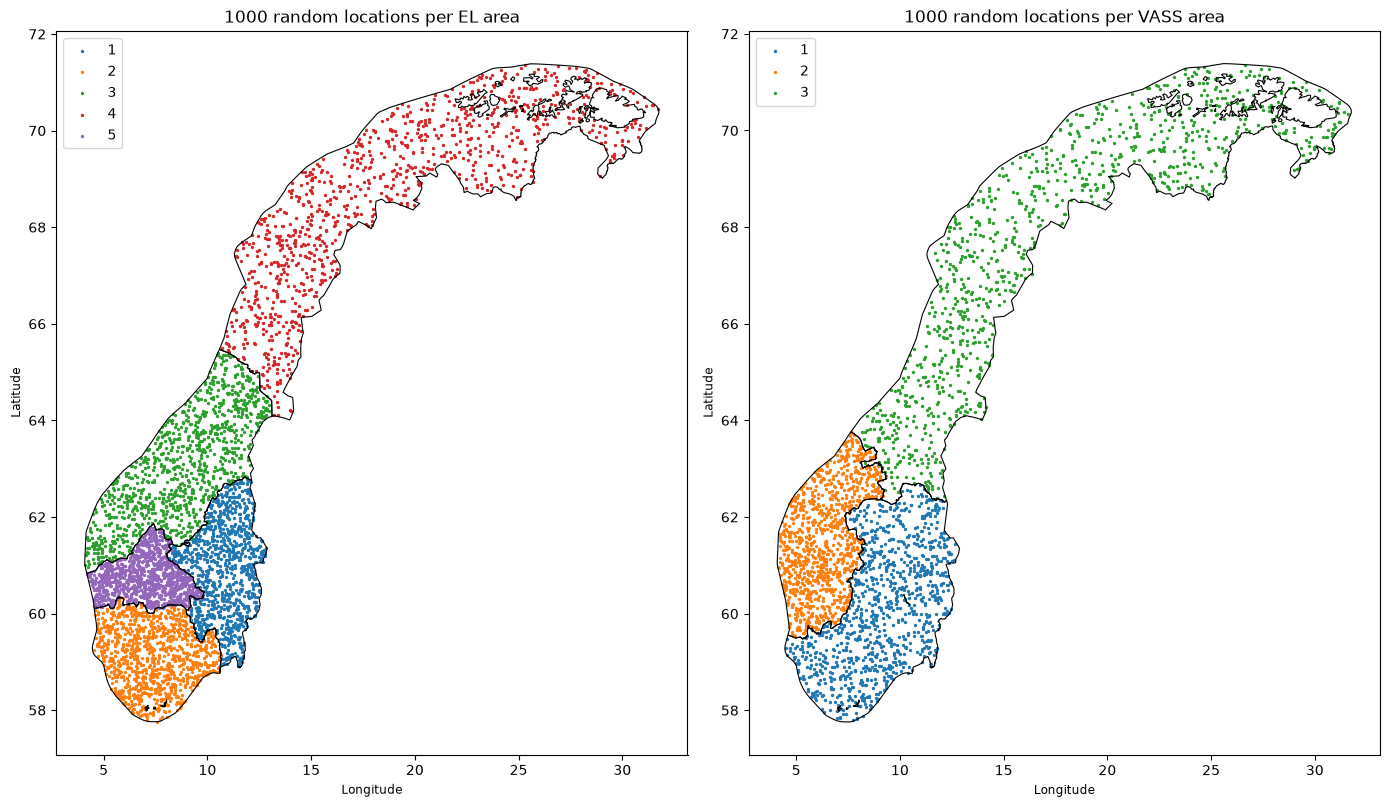

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

for ax, area_type in zip(axes, ["EL", "VASS"]):
    # Area borders in black, points coloured by area
    areas[areas["area_type"] == area_type].to_crs(4326).boundary.plot(ax=ax, color="black", linewidth=0.8)
    subset = locations[locations["area_type"] == area_type]
    subset.plot(ax=ax, column="area_nr", categorical=True, legend=True, markersize=2)
    ax.set_title(f"{POINTS_PER_AREA} random locations per {area_type} area")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# API: Open-Meteo (ERA5)
- API: https://open-meteo.com/en/docs/historical-weather-api
- Data: ERA5 reanalysis, hourly, on a 0.25° grid (~25 km). Licence CC BY 4.0

**Choices:**
- Variables: temperature, precipitation, rain, snowfall, snow depth and evaporation. Rain reaches the reservoirs right away, snow waits until it melts, and evaporation is water lost. The full list is in `ind320.openmeteo`.
- Time in UTC, like the ENTSO-E data.
- Fewer locations, and grid cells instead of one request per location. The free API allows 10,000 calls per day, and one location for a full year counts as about 26 calls. 1000 locations would be about 26,000 calls for one region, so the number is cut to 100 per area. On top of that, many locations fall in the same ERA5 grid cell (0.25°, about 28 × 12 km here) and would get the same data, so each location is snapped to the nearest grid point and each cell is downloaded once. `n_points` says how many of the locations fell in each cell, so the cells can be weighted when averaging over the region.
- Open-Meteo's adjustment of temperature to each point's exact elevation is turned off (`elevation=nan`), so all points in a cell get the cell's own value. This makes the snapping lossless.
- The download takes about 25 minutes per region and year, so it is saved as a local backup (`data/weather_<region>_<year>.parquet`, not in git).

In [ ]:
from ind320 import openmeteo


# "NO3" -> ("EL", 3), "VASS1" -> ("VASS", 1)
def parse_region_id(region_id):
    if region_id.startswith("VASS"):
        return "VASS", int(region_id[4:])
    if region_id.startswith("NO"):
        return "EL", int(region_id[2:])
    raise ValueError(f"Unknown region: {region_id}. Use NO1-NO5 or VASS1-VASS3")


# Downloads hourly ERA5 data for one region and time interval.
# Looks up the region's random locations, snaps them to the ERA5 grid and downloads each grid cell once
def download_region_weather(region_id, start, end):
    area_type, area_nr = parse_region_id(region_id)
    points = locations[(locations["area_type"] == area_type) & (locations["area_nr"] == area_nr)]
    if points.empty:
        raise ValueError(f"No locations for {region_id}")

    # Grid cells, with how many of the random locations fell in each
    grid = pd.DataFrame({
        "latitude": openmeteo.snap_to_grid(points["lat"]),
        "longitude": openmeteo.snap_to_grid(points["lon"]),
    })
    cells = grid.value_counts().rename("n_points").reset_index()
    print(f"{region_id}: {len(points)} locations -> {len(cells)} ERA5 grid cells")

    weather = openmeteo.fetch_weather(list(zip(cells["latitude"], cells["longitude"])), start, end)
    weather = weather.merge(cells, on=["latitude", "longitude"])
    weather.insert(0, "region", region_id)
    return weather

### NO3 for 2024

In [ ]:
# Downloads NO3 for 2024 (takes about 25 minutes), or loads the local backup if it exists.
# Delete the backup file to download fresh data
REGION = "NO3"
YEAR = 2024
WEATHER_PATH = DATA_PATH / f"weather_{REGION}_{YEAR}.parquet"

if WEATHER_PATH.exists():
    weather_no3 = pd.read_parquet(WEATHER_PATH)
    print(f"Loaded backup from {WEATHER_PATH}")
else:
    weather_no3 = download_region_weather(REGION, f"{YEAR}-01-01", f"{YEAR}-12-31")
    weather_no3.to_parquet(WEATHER_PATH)
    print(f"Downloaded from Open-Meteo and saved backup to {WEATHER_PATH}")

# Every grid cell should have 8784 hours (2024 is a leap year: 366 x 24)
print(weather_no3.shape)
print("Period:", weather_no3["time"].min(), "to", weather_no3["time"].max())
print("Locations covered:", weather_no3.groupby(["latitude", "longitude"])["n_points"].first().sum(), "of", POINTS_PER_AREA)
weather_no3.groupby(["latitude", "longitude"]).size().describe()

### Sanity check: region average, with each grid cell weighted by how many locations fell in it.
### Temperature as a daily mean, precipitation as a daily sum
variables = openmeteo.HOURLY_VARIABLES
weighted = weather_no3[variables].mul(weather_no3["n_points"], axis=0)
total_points = weather_no3.groupby("time")["n_points"].sum()
region_mean = weighted.groupby(weather_no3["time"]).sum().div(total_points, axis=0)

daily_temperature = region_mean["temperature_2m"].resample("1D").mean()
daily_precipitation = region_mean["precipitation"].resample("1D").sum()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
daily_temperature.plot(ax=axes[0], title=f"{REGION} {YEAR}: daily mean temperature")
axes[0].set_ylabel("°C")
daily_precipitation.plot(ax=axes[1], title=f"{REGION} {YEAR}: daily precipitation")
axes[1].set_ylabel("mm")
plt.tight_layout()
plt.show()